# M4.7 · 指数增强与市场中性

> 公募/私募量化的两大产品形态：**指数增强**在控制跟踪误差的前提下跑赢基准；**市场中性**通过多空对冲剥离市场风险，赚取纯 alpha。
> 两者都围绕「相对基准的主动风险」而非绝对风险展开。

## 一、关键指标与模型

1. **跟踪误差** $\,TE=\sqrt{(w-w_b)^\top\Sigma(w-w_b)}$（年化）；
2. **超额收益** $\,\alpha=(w-w_b)^\top\mu$；**信息比率** $\,IR=\alpha/TE$；
3. **指数增强**：在 $TE\le TE_{\max}$、fully invested、long-only 下最大化主动效用；
4. **市场中性**：允许负权重，约束 beta 中性 $w^\top\beta=0$、美元中性 $\sum w=0$、总敞口 $\lVert w\rVert_1\le G$；
5. **股指期货对冲**：合约数 $N=\lfloor\beta\cdot V/(p_{idx}\cdot m)\rfloor$，注意基差与展期成本。

## 二、指数增强

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np, pandas as pd
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from port_lab2 import products
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$close'], start_time='2018-01-01', freq='day')
cl = raw['$close'].unstack('instrument')
ret = cl.pct_change(fill_method=None)
r50 = ret.iloc[-750:, :50].dropna(axis=1)
S50 = np.cov(r50.values, rowvar=False); mu50 = r50.mean().values
wb = np.ones(50)/50
w_enh = products.enhanced_index_portfolio(pd.Series(mu50, index=r50.columns),
        pd.DataFrame(S50), pd.Series(wb, index=r50.columns), te_max=0.08)
te = products.tracking_error(w_enh, S50, wb); ex = products.excess_return(w_enh, mu50, wb)
print('指增: sum=%.4f TE=%.4f 年化超额=%.4f IR=%.3f' % (w_enh.sum(), te, ex, ex/te))
te_grid = [0.04, 0.06, 0.08, 0.10]
ir_rows = []
for t in te_grid:
    w = products.enhanced_index_portfolio(pd.Series(mu50, index=r50.columns),
        pd.DataFrame(S50), pd.Series(wb, index=r50.columns), te_max=t)
    e = products.excess_return(w, mu50, wb); tt = products.tracking_error(w, S50, wb)
    ir_rows.append((t, e, tt, e/tt))
ir_df = pd.DataFrame(ir_rows, columns=['TE上限', '超额', '实际TE', 'IR']).set_index('TE上限')
print(ir_df)

[27088:MainThread](2026-11-05 14:37:40,123) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[27088:MainThread](2026-11-05 14:37:41,940) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[27088:MainThread](2026-11-05 14:37:41,942) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


指增: sum=1.0000 TE=0.0800 年化超额=0.1833 IR=2.292
            超额  实际TE        IR
TE上限                          
0.04  0.112374  0.04  2.809339
0.06  0.152183  0.06  2.536389
0.08  0.183332  0.08  2.291652
0.10  0.209317  0.10  2.093174


## 三、市场中性与期货对冲

In [2]:
mkt = r50.mean(axis=1)
betas = pd.Series({c: np.cov(r50[c].dropna(), mkt.loc[r50[c].dropna().index])[0, 1]
                   / np.var(mkt) for c in r50.columns})
w_mn = products.market_neutral_portfolio(pd.Series(mu50, index=r50.columns),
        pd.DataFrame(S50), betas, gross_limit=1.0)
exp = products.gross_net_exposure(w_mn)
print('中性: net=%.4f beta=%.4f gross=%.4f' % (exp['net'], w_mn@betas.values, exp['gross']))
n_if = products.index_hedge_contracts(1.0, 1e7, 3800, 300)
print('IF 对冲手数=%d（点位3800、乘数300）' % n_if)

中性: net=0.0000 beta=-0.0000 gross=1.0000
IF 对冲手数=8（点位3800、乘数300）


## 四、可视化

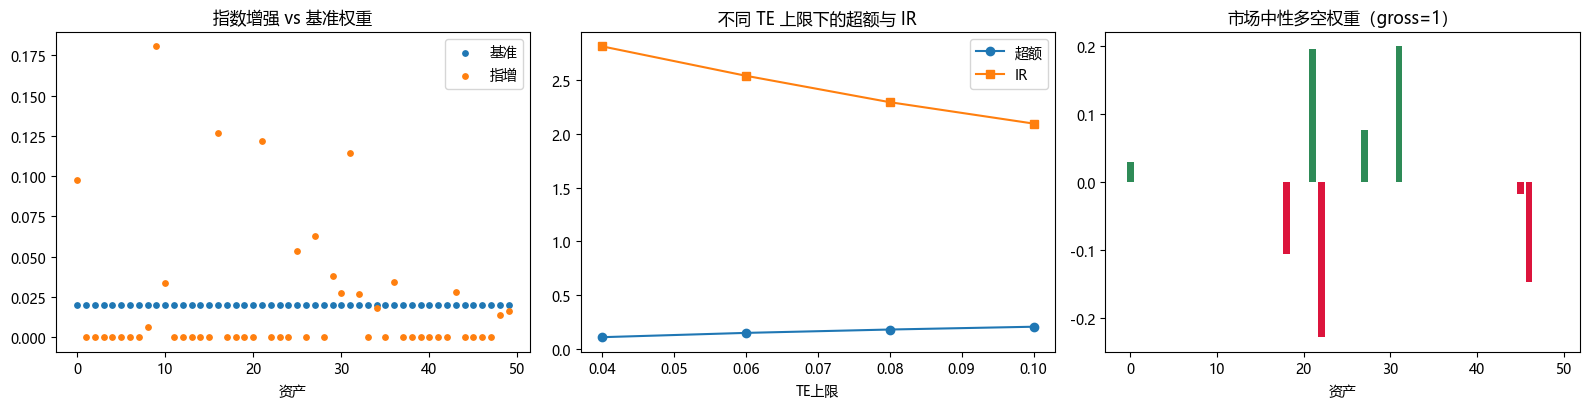

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
xx = np.arange(50)
ax[0].scatter(xx, wb, s=15, label='基准')
ax[0].scatter(xx, w_enh.values, s=15, label='指增')
ax[0].set_title('指数增强 vs 基准权重'); ax[0].legend(); ax[0].set_xlabel('资产')
ax[1].plot(ir_df.index, ir_df['超额'], 'o-', label='超额')
ax[1].plot(ir_df.index, ir_df['IR'], 's-', label='IR')
ax[1].set_title('不同 TE 上限下的超额与 IR'); ax[1].set_xlabel('TE上限'); ax[1].legend()
colors = ['crimson' if v < 0 else 'seagreen' for v in w_mn.values]
ax[2].bar(np.arange(50), w_mn.values, color=colors)
ax[2].set_title('市场中性多空权重（gross=1）'); ax[2].set_xlabel('资产')
plt.tight_layout(); plt.show()

## 五、面试要点

- **TE 与 IR 的关系？** TE 是主动风险，IR 衡量每单位主动风险的超额收益，是指增产品的核心考核指标；放宽 TE 上限通常提高超额但 IR 不一定单调。
- **指数增强为何一般 long-only？** 公募约束 + 融券成本；私募中性才用多空。
- **中性组合为何要同时约束 beta、美元、gross？** 只约束 sum=0 仍可能有 beta 暴露或杠杆发散（无 gross 约束时本数据杠杆曾达 9.4 倍）。
- **期货对冲的现实成本？** 基差（贴水/升水）、保证金、展期成本都会侵蚀 alpha；合约数需向下取整。

## 六、练习

1. 改变 gross_limit 观察中性组合的多空规模与预期收益。
2. 用市值权重替代等权基准，重新计算 TE 与 IR。
3. 推导指数增强的 KKT，说明 TE 约束为何通常是「紧」的。
4. 若 IF 长期贴水，对冲组合的净收益会如何变化？